# 6. Avaliação

**Pergunta deste notebook:** as músicas geradas se parecem com as reais? E a LSTM é melhor que o baseline de Markov?

Não existe "resposta certa" para comparar nota a nota: as músicas são geradas do zero, então a música gerada número 10 não tem nada a ver com a música real número 10. O que comparamos são **conjuntos**: as 1.854 geradas de cada sistema contra as 1.854 reais do teste. Fazemos isso em três níveis:

| Nível | O que mede | Métricas |
|---|---|---|
| **Partitura** | propriedades musicais de cada música | pitch entropy, scale consistency, groove consistency; depois OA e KS entre distribuições |
| **Áudio** | o som sintetizado, visto por uma rede de áudio | FAD, KLD |
| **Pessoas** | o que ouvintes acham | teste de escuta (à parte) |

Sistemas comparados: a LSTM com nlm e com grid_block, cada uma com T = 1 e com top-k 10, e o baseline de **Markov** (`evaluation/markov_baseline.py`), que sorteia cada nota olhando só para a anterior.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbkit as k
from pico8_metrics import evaluate_song_data

k.estilo()
SISTEMAS = ["lstm-grid_block-k10", "lstm-grid_block-t1", "lstm-nlm-t1", "lstm-nlm-k10", "markov"]
METRICAS = {"pitch_entropy": "pitch entropy", "scale_consistency": "scale consistency",
            "groove_consistency": "groove consistency"}

## Primeiro, ouvir e ver

Uma música real, uma da LSTM (grid_block, top-k 10) e uma do Markov.

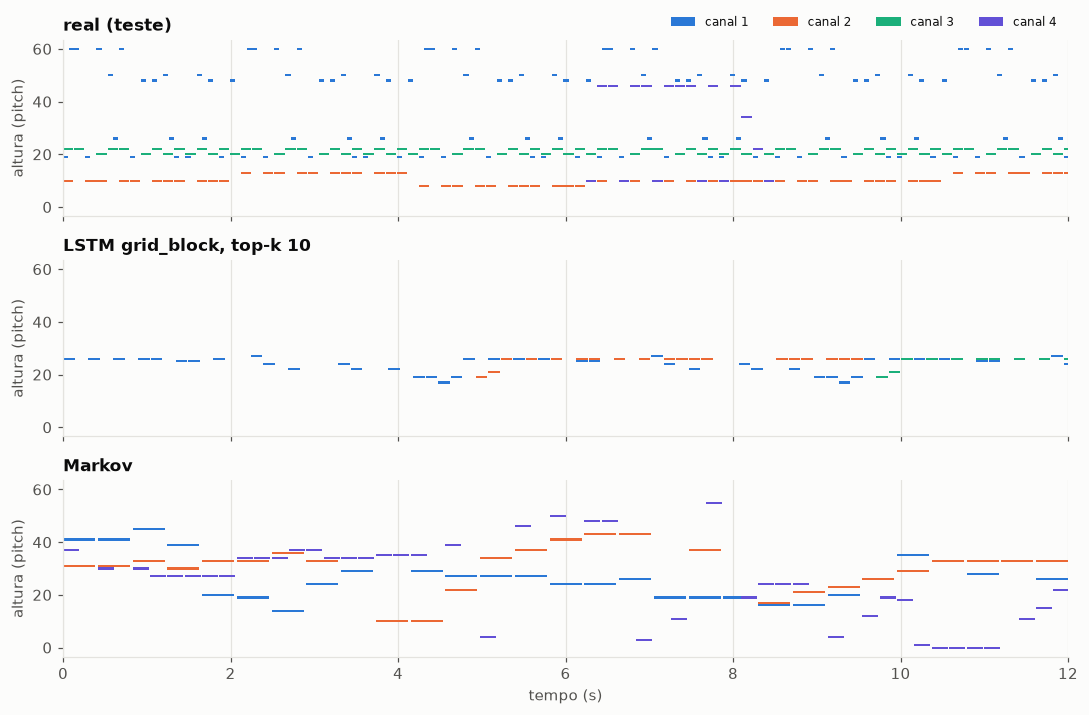

In [2]:
def bom_exemplo(musicas):
    """Primeira música com 3 canais nos primeiros 12 s e poucas notas no extremo grave (percussão)."""
    for m in musicas:
        ns = k.notas(m)
        if (len({n[0] for n in k.notas(m, 12)}) >= 3 and len(ns) > 80 and k.duracao(m) >= 12
                and sum(n[3] < 5 for n in ns) < 0.1 * len(ns)):
            return m
    return musicas[0]

exemplos = {"real (teste)": bom_exemplo(k.musicas_reais(200)),
            "LSTM grid_block, top-k 10": bom_exemplo(k.musicas_geradas("grid_block-k10", 200)),
            "Markov": bom_exemplo(k.musicas_geradas("markov", 200))}
fig, axes = plt.subplots(3, 1, figsize=(10, 6.6), sharex=True, sharey=True)
for ax, (rotulo, m) in zip(axes, exemplos.items()):
    k.piano_roll(m, ax, segundos=12, titulo=rotulo, legenda=ax is axes[0])
    if ax is not axes[-1]:
        ax.set_xlabel("")
fig.tight_layout()
plt.show()

Real:

In [3]:
k.tocar(exemplos["real (teste)"])

LSTM (grid_block, top-k 10):

In [4]:
k.tocar(exemplos["LSTM grid_block, top-k 10"])

Markov:

In [5]:
k.tocar(exemplos["Markov"])

## Três medidas por música

Calculadas pela partitura (`evaluation/pico8_metrics.py`), seguindo Wu & Yang (2020):

- **Pitch entropy (PE):** quão variadas são as alturas usadas. Baixa = poucas notas diferentes; alta = notas espalhadas.
- **Scale consistency (SC):** a maior fração das notas que cabe numa mesma escala maior (em qualquer tom). Perto de 1 = soa "afinada" num tom.
- **Groove consistency (GC):** o quanto o padrão rítmico de um pattern se repete no seguinte. Perto de 1 = ritmo estável. Só existe para músicas com mais de um pattern.

Nenhuma delas é "quanto maior, melhor". O que queremos é que as geradas tenham valores **parecidos com os das reais**.

In [6]:
linhas = []
for rotulo, m in exemplos.items():
    r = evaluate_song_data(m)
    linhas.append({"música": rotulo, **{nome: "—" if r[c] is None else k.br(r[c]) for c, nome in METRICAS.items()}})
k.tabela(linhas)

| música | pitch entropy | scale consistency | groove consistency |
|---|---|---|---|
| real (teste) | 2,46 | 0,92 | 0,99 |
| LSTM grid_block, top-k 10 | 3,03 | 0,88 | 0,74 |
| Markov | 3,43 | 0,77 | 1,00 |

## De músicas para distribuições

Uma música sozinha diz pouco. Calculamos as três medidas para todas as músicas de cada sistema (os arquivos em `artefatos/resultados/simbolico/por-musica/`) e comparamos os **histogramas**.

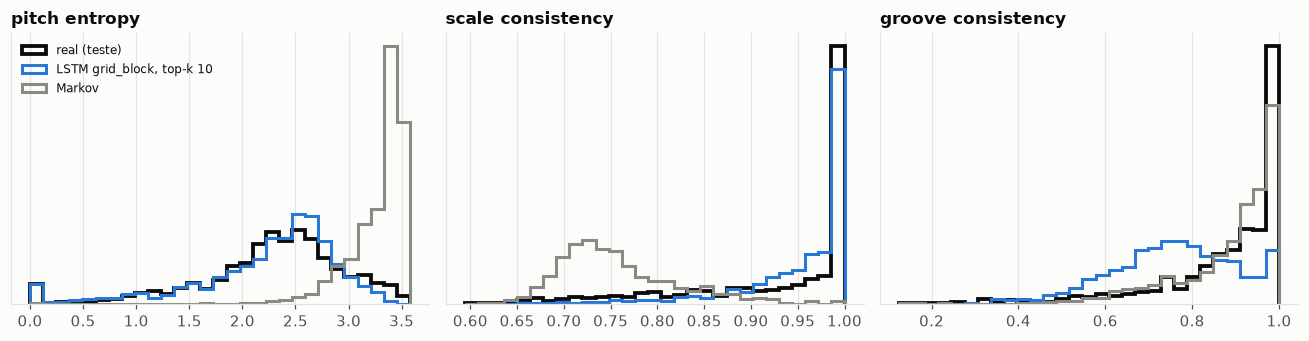

In [7]:
por_musica = {s: k.metricas_por_musica(s) for s in ["real_test"] + SISTEMAS}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (chave, titulo) in zip(axes, METRICAS.items()):
    todos = k.coluna(por_musica["real_test"], chave)
    bins = np.linspace(todos.min(), todos.max(), 30)
    for s, estilo in [("real_test", dict(lw=2.5)), ("lstm-grid_block-k10", dict(lw=2)), ("markov", dict(lw=2))]:
        ax.hist(k.coluna(por_musica[s], chave), bins=bins, density=True, histtype="step",
                color=k.cor(s), label=k.nome(s), **estilo)
    ax.set_title(titulo, loc="left"); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

A curva da LSTM acompanha a das reais; a do Markov foge, principalmente em pitch entropy e scale consistency (ele usa notas demais e fora de escala).

Para resumir "o quanto duas curvas coincidem" num número, usamos duas medidas (Yang & Lerch, 2020):

- **OA (overlapped area):** a área em comum entre as duas curvas. 1 = idênticas. **Maior é melhor.**
- **KS (Kolmogorov-Smirnov):** a maior distância entre as curvas acumuladas. 0 = idênticas. **Menor é melhor.**

In [8]:
comp = [r for r in k.ler_csv(k.ARTEFATOS / "resultados" / "simbolico" / "distribution_compare.csv")
        if r["metric"] in METRICAS]
resumo = {s: {"oa": np.mean([float(r["oa"]) for r in comp if r["system"] == s]),
              "ks": np.mean([float(r["ks"]) for r in comp if r["system"] == s])} for s in SISTEMAS}
k.tabela([{"sistema": k.nome(s), "OA médio (↑)": k.br(resumo[s]["oa"]), "KS médio (↓)": k.br(resumo[s]["ks"]),
           **{f"OA {nome}": k.br(float(next(r["oa"] for r in comp if r["system"] == s and r["metric"] == c)))
              for c, nome in METRICAS.items()}} for s in SISTEMAS])

| sistema | OA médio (↑) | KS médio (↓) | OA pitch entropy | OA scale consistency | OA groove consistency |
|---|---|---|---|---|---|
| LSTM grid_block, top-k 10 | 0,89 | 0,22 | 0,98 | 0,89 | 0,79 |
| LSTM grid_block, T = 1 | 0,86 | 0,37 | 0,97 | 0,89 | 0,74 |
| LSTM nlm, T = 1 | 0,83 | 0,35 | 0,99 | 0,87 | 0,64 |
| LSTM nlm, top-k 10 | 0,81 | 0,38 | 0,92 | 0,84 | 0,66 |
| Markov | 0,79 | 0,53 | 0,78 | 0,65 | 0,95 |

Leitura:

- O **grid_block com top-k 10** é o mais próximo das reais (OA 0,89; KS 0,22). Todos os sistemas da LSTM ficam à frente do Markov na média.
- O Markov vai bem em groove consistency (OA 0,95) e mal nas outras duas: ele copia o ritmo estável, mas não a escolha de notas.
- A groove consistency só é definida para músicas com mais de um pattern (673 das 1.854 reais), então ela pesa menos do que parece.

## No áudio: FAD e KLD

As medidas acima olham a partitura. Para olhar o **som**, sintetizamos clipes de 10 s e passamos por uma rede de áudio pré-treinada (CLAP), que transforma cada clipe num vetor.

- **FAD (Fréchet Audio Distance):** distância entre a nuvem de vetores das geradas e a das reais. **Menor é melhor.**
- **KLD:** diferença entre os tipos de som que um classificador reconhece nos dois conjuntos. **Menor é melhor.**

O FAD nunca dá zero, nem entre dois conjuntos de músicas reais. Por isso medimos também o **piso**: as músicas reais de validação contra as de teste.

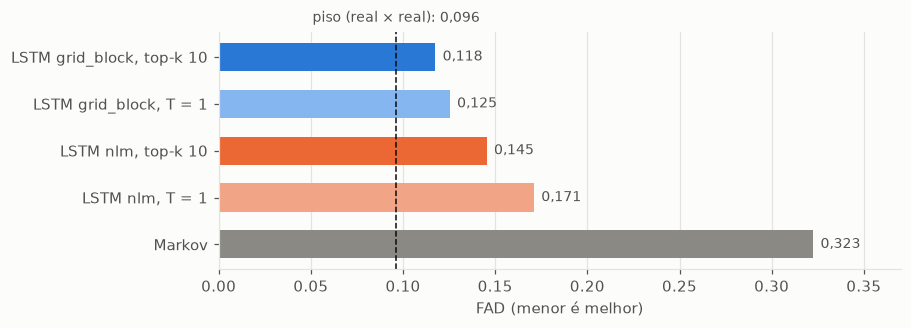

| sistema | FAD (↓) | KLD (↓) | clipes |
|---|---|---|---|
| LSTM grid_block, top-k 10 | 0,118 | 0,040 | 200 |
| LSTM grid_block, T = 1 | 0,125 | 0,038 | 200 |
| LSTM nlm, top-k 10 | 0,145 | 0,072 | 200 |
| LSTM nlm, T = 1 | 0,171 | 0,085 | 200 |
| Markov | 0,323 | 0,213 | 200 |

In [9]:
audio = {r["set"]: r for r in k.ler_csv(k.ARTEFATOS / "resultados" / "audio" / "audio_metrics.csv")}
ordem = sorted(SISTEMAS, key=lambda s: float(audio[s]["fad"]))
piso = float(audio["real_val"]["fad"])

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh([k.nome(s) for s in ordem], [float(audio[s]["fad"]) for s in ordem],
        color=[k.cor(s) for s in ordem], height=0.6)
for i, s in enumerate(ordem):
    ax.text(float(audio[s]["fad"]) + 0.004, i, k.br(float(audio[s]["fad"]), 3), va="center", fontsize=9, color=k.TINTA2)
ax.axvline(piso, color=k.TINTA, lw=1, ls="--")
ax.text(piso, -0.75, f"piso (real × real): {k.br(piso, 3)}", ha="center", fontsize=9, color=k.TINTA2)
ax.invert_yaxis(); ax.set_xlim(0, 0.37); ax.set_xlabel("FAD (menor é melhor)"); ax.grid(axis="y", visible=False)
plt.show()
k.tabela([{"sistema": k.nome(s), "FAD (↓)": k.br(float(audio[s]["fad"]), 3), "KLD (↓)": k.br(float(audio[s]["kld"]), 3),
           "clipes": audio[s]["clips"]} for s in ordem])

O áudio conta a mesma história da partitura: o grid_block fica perto do piso (0,118 contra 0,096) e o Markov fica longe (0,323).

## Ressalvas

- Os números de áudio vêm de **200 clipes de 10 s por sistema** (referência: 400 músicas do teste), não das 1.854 músicas inteiras.
- O **top-k 10 não foi ajustado na validação**.
- A diferença entre grid_block T = 1 e top-k 10 no FAD é pequena (0,125 contra 0,118), da ordem do desvio da própria medida.
- Métrica automática não substitui ouvido: por isso existe o teste de escuta.

## O que levar daqui

- Comparamos conjuntos, não pares de músicas.
- Na partitura (OA/KS) e no áudio (FAD/KLD), a ordem é a mesma: **LSTM grid_block > LSTM nlm > Markov**.
- Sugestão de sistema principal para o artigo: **LSTM grid_block com top-k 10**.

As tabelas completas e os comandos para reproduzir estão em [`docs/RESULTADOS.md`](../docs/RESULTADOS.md); o mapa de todas as etapas, em [`docs/ETAPAS.md`](../docs/ETAPAS.md).

**Experimente:** troque os sistemas do histograma; calcule as três medidas para uma música que você gerou no notebook 5; ouça outros exemplos mudando `bom_exemplo`.

Anterior: [5. Geração](05_geracao.ipynb).